# 纠缠熵 (EE) 汇总

`collect_EE("./")` 遍历本文件夹下**所有 `L=*` 子文件夹**（如 `L=6/`、`L=12/`），
把每个子文件夹里所有 `*.csv` 汇总起来（每个文件 = 一次 QMC 测量，每行 = 一个 sweep 的样本）：

- **子文件夹名里 `L` 后面的数字** → `L`（例如 `L=6/FreeHCL6_β0.7.csv` → `L = 6`）
- **文件名里 `β` 后面的数字** → `beta`（例如 `FreeHCL6_β0.7.csv` → `beta = 0.7`）
- **第 1 列** → `Half`
- **第 2 列** → `HalfHalf`

文件名里自带的 `L` 只用于校验，和文件夹名不一致时给 warning，以文件夹名为准；
直接放在本文件夹下（不在任何 `L=*` 里）的 csv 会被忽略并 warning。

对每一列，设第 $i$ 个 sweep 的样本为 $x_i$，则

$$\mathrm{EE} = \overline{-\log x} = \frac{1}{N}\sum_{i=1}^{N}\bigl(-\log x_i\bigr),\qquad
\mathrm{dEE} = \frac{\sigma_{-\log x}}{\sqrt{N}}$$

其中 $\sigma_{-\log x}$ 是**逐样本值 $-\log x_i$** 的样本标准差（`ddof=1`）、$N$ 为样本数。

注意是**先对每个样本取 $-\log$、再求平均**，不是先求平均再取 $-\log$（即不是 $-\log\overline{x}$）。
两者物理含义不同：前者是"逐轨迹算熵、再对轨迹平均"，后者是"先把密度矩阵平均、再算熵"。

最终返回**长表** DataFrame：`L | beta | type | EE | dEE`，`type ∈ {"Half", "HalfHalf"}`。

绘图编码：

- **颜色** → csv 的列（`Half` / `HalfHalf`）；
- **线型 + marker** → 子文件夹名里 `L` 后面的数字；
- **legend 文字**形如 `L=6 Half`、`L=6 HalfHalf`、`L=8 Half` …（每个 `(L, 列)` 组合一项）。

`collect_EE(..., throw=n)` 会**丢掉每个文件每一列的前 `n` 行**（热化 / 平衡化阶段的数据），
这些行不参与均值和误差的计算——只影响计算，不会改动 csv 文件本身。默认 `throw=0`。


In [1]:
# 依赖：pandas / numpy（画图还需要 matplotlib）
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

"csv 第 c 列对应的 legend 名字"
COLNAMES = ["Half", "HalfHalf"]

# 文件名里数字的写法：可选正负号、小数、科学计数法
_NUM = r"[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?"


def extract_beta(filename):
    """
    取**紧跟在 β 后面**的那个数字，例如：
        FreeHCL6_β0.7.csv     -> 0.7
        FreeHCL6_beta=1.0.csv -> 1.0
    文件名里只有唯一一个数字时（老命名），退化为取那个数字并给警告。
    一个数字都找不到时报错——beta 是横轴，不能缺。
    """
    name = Path(filename).name
    m = re.search(r"(?:β|beta)\s*[=_]?\s*(" + _NUM + r")", name, re.IGNORECASE)
    if m:
        return float(m.group(1))

    nums = re.findall(_NUM, name)
    if len(nums) == 1:
        warnings.warn(f'文件名 {filename} 里没有 "β"，退而取唯一数字 "{nums[0]}" 作为 beta')
        return float(nums[0])
    raise ValueError(
        f'文件名 {filename} 里找不到紧跟在 "β" 后面的数字（共找到 {len(nums)} 个数字 {nums}），'
        f"无法确定 beta"
    )


def extract_L(filename):
    """
    取**紧跟在 L 后面**的那个数字，例如 FreeHCL6_β0.7.csv -> 6.0。
    找不到时给警告并返回 NaN（L 只用于第二个 legend，缺了不影响主曲线）。
    """
    m = re.search(r"[Ll]\s*[=_]?\s*(" + _NUM + r")", Path(filename).name)
    if not m:
        warnings.warn(f'文件名 {filename} 里找不到紧跟在 "L" 后面的数字，L 记为 NaN')
        return np.nan
    return float(m.group(1))


def read_two_cols(path):
    """
    读入 csv 的前两列，返回 N×2 的 float 数组；
    表头 / 非数值行 / 空行会被自动丢掉。文件为空时返回 0×2 的空数组。
    """
    try:
        raw = pd.read_csv(path, header=None)
    except pd.errors.EmptyDataError:
        return np.empty((0, 2), dtype=float)
    if raw.shape[1] == 0:
        return np.empty((0, 2), dtype=float)

    raw = raw.iloc[:, :2]
    # errors="coerce" 把表头等非数值内容变成 NaN，dropna 再丢掉这些行
    num = raw.apply(pd.to_numeric, errors="coerce").dropna()
    return num.to_numpy(dtype=float)


def ee_and_error(x, method="propagate"):
    """
    EE = mean(-log(x))，即**先对每个样本取 -log，再求平均**（"先算熵、后平均"）。
    注意不是 -log(mean(x))——后者是"先平均、后算熵"，两个量物理含义不同。
    返回 (EE, dEE)。

    - method="propagate"：dEE = std(-log(x), ddof=1) / sqrt(N)
    - method="jackknife"：留一法。因为这里统计量本身就是平均值（线性量），
      jackknife 与 propagate 结果在数学上完全相同，保留只是为了接口一致。
    """
    x = np.asarray(x, dtype=float).ravel()
    n0 = x.size
    if n0 == 0:
        return np.nan, np.nan

    ok = np.isfinite(x) & (x > 0)          # -log 的定义域：x > 0
    if not ok.all():
        warnings.warn(f"有 {n0 - int(ok.sum())}/{n0} 个样本 <= 0 或非有限，已丢弃（-log 定义域）")
    x = x[ok]
    n = x.size
    if n == 0:
        return np.nan, np.nan

    y = -np.log(x)                          # 逐样本的熵
    ee = y.mean()

    if method == "propagate":
        sd = y.std(ddof=1) if n > 1 else 0.0
        return ee, sd / np.sqrt(n)
    elif method == "jackknife":
        if n < 2:
            return ee, np.nan
        theta = (y.sum() - y) / (n - 1)
        return ee, np.sqrt((n - 1) / n * ((theta - theta.mean()) ** 2).sum())
    else:
        raise ValueError(f"未知的 method = {method}（可选 'propagate' 或 'jackknife'）")


In [2]:
def collect_EE(directory=None, method="propagate", pattern=r"\.csv$", throw=0,
               folder_pattern="L=*"):
    """
    遍历 directory 下所有匹配 folder_pattern 的子文件夹（如 L=6/、L=12/），
    把每个子文件夹里所有匹配 pattern 的文件汇总成一个 DataFrame。

    L 取自**文件夹名**（L=6 → 6.0）；文件名里自带的 L 只用于校验，不一致时给 warning。

    throw：每个文件**每一列都丢掉前 throw 行**（热化 / 平衡化阶段的数据），
           只影响计算，不会改动 csv 文件本身。默认 throw=0。

    返回列：L | beta | type | EE | dEE（按 L, type, beta 排序）。
    """
    if throw < 0:
        raise ValueError(f"throw 必须 >= 0，收到 {throw}")

    directory = Path(directory) if directory is not None else Path.cwd()
    folders = sorted(p for p in directory.glob(folder_pattern) if p.is_dir())
    if not folders:
        warnings.warn(f"在 {directory} 下没有找到匹配 {folder_pattern} 的子文件夹")
        return pd.DataFrame(columns=["L", "beta", "type", "EE", "dEE"])

    stray = [p.name for p in directory.glob("*")
             if p.is_file() and re.search(pattern, p.name, re.IGNORECASE)]
    if stray:
        warnings.warn(f"{directory} 下直接放着的 {len(stray)} 个文件不属于任何 "
                      f"{folder_pattern} 子文件夹，会被忽略：{stray[:3]}"
                      f"{' 等' if len(stray) > 3 else ''}")

    rows = []
    for folder in folders:
        Lval = extract_L(folder.name)
        files = sorted(p for p in folder.iterdir()
                       if p.is_file() and re.search(pattern, p.name, re.IGNORECASE))
        if not files:
            warnings.warn(f"{folder.name}/ 下没有匹配 {pattern} 的文件")
            continue

        for f in files:
            data = read_two_cols(f)
            if data.size == 0:
                warnings.warn(f"跳过空文件 / 无法解析：{f.name}")
                continue
            if throw >= data.shape[0]:
                warnings.warn(f"{f.name} 只有 {data.shape[0]} 行，扔掉前 {throw} 行后没数据了，跳过")
                continue
            data = data[throw:, :]     # 丢掉前 throw 行（各列同步），csv 文件本身不动

            beta = extract_beta(f.name)
            Lfile = extract_L(f.name)
            if not np.isnan(Lfile) and Lfile != Lval:
                warnings.warn(f"{folder.name}/{f.name} 里写的 L={Lfile:g} 与文件夹名 "
                              f"L={Lval:g} 不一致，以文件夹名为准")

            for c, name in enumerate(COLNAMES):
                if c >= data.shape[1]:
                    continue           # 文件只有一列时跳过 HalfHalf
                ee, dee = ee_and_error(data[:, c], method=method)
                if np.isnan(ee):
                    warnings.warn(f"{folder.name}/{f.name} 的 {name} 列无法计算 EE，跳过")
                    continue
                rows.append((Lval, beta, name, ee, dee))

    df = pd.DataFrame(rows, columns=["L", "beta", "type", "EE", "dEE"])
    if not df.empty:
        df = df.sort_values(["L", "type", "beta"]).reset_index(drop=True)
    return df


In [3]:
# 遍历 ./ 下所有 L=* 子文件夹里的所有 csv
df = collect_EE("./", throw=000)         # throw=n：丢掉每个文件每列的前 n 行（热化数据）
df


,L,beta,type,EE,dEE
0,6.0,0.0,Half,3.630173,1.332334e-17
1,6.0,0.1,Half,3.605684,5.703992e-04
2,6.0,0.2,Half,3.535375,1.130178e-03
3,6.0,0.3,Half,3.425147,1.641549e-03
4,6.0,0.4,Half,3.278334,2.119592e-03
...,...,...,...,...,...
179,18.0,2.6,HalfHalf,0.732934,1.234193e-02
180,18.0,2.7,HalfHalf,0.590993,1.125505e-02
181,18.0,2.8,HalfHalf,0.488625,1.112952e-02
182,18.0,2.9,HalfHalf,0.379683,9.992575e-03


In [4]:
# （可选）转成宽表，方便直接画图：行 = (L, beta)，列 = Half / HalfHalf
wide = df.pivot_table(index=["L", "beta"], columns="type", values="EE")
wide_dee = df.pivot_table(index=["L", "beta"], columns="type", values="dEE")
wide_dee.columns = [f"dEE_{c}" for c in wide_dee.columns]
wide = wide.join(wide_dee)
wide

Half  HalfHalf      dEE_Half  dEE_HalfHalf
L    beta                                                
6.0  0.0   3.630173  3.341644  1.332334e-17  1.332334e-17
     0.1   3.605684  3.314760  5.703992e-04  5.058574e-04
     0.2   3.535375  3.238382  1.130178e-03  1.010111e-03
     0.3   3.425147  3.119294  1.641549e-03  1.514000e-03
     0.4   3.278334  2.965488  2.119592e-03  2.002389e-03
...             ...       ...           ...           ...
18.0 2.6   0.904879  0.732934  1.321080e-02  1.234193e-02
     2.7   0.727379  0.590993  1.224646e-02  1.125505e-02
     2.8   0.600649  0.488625  1.211451e-02  1.112952e-02
     2.9   0.466543  0.379683  1.097709e-02  9.992575e-03
     3.0   0.348353  0.276698  9.927790e-03  8.635850e-03

[92 rows x 4 columns]

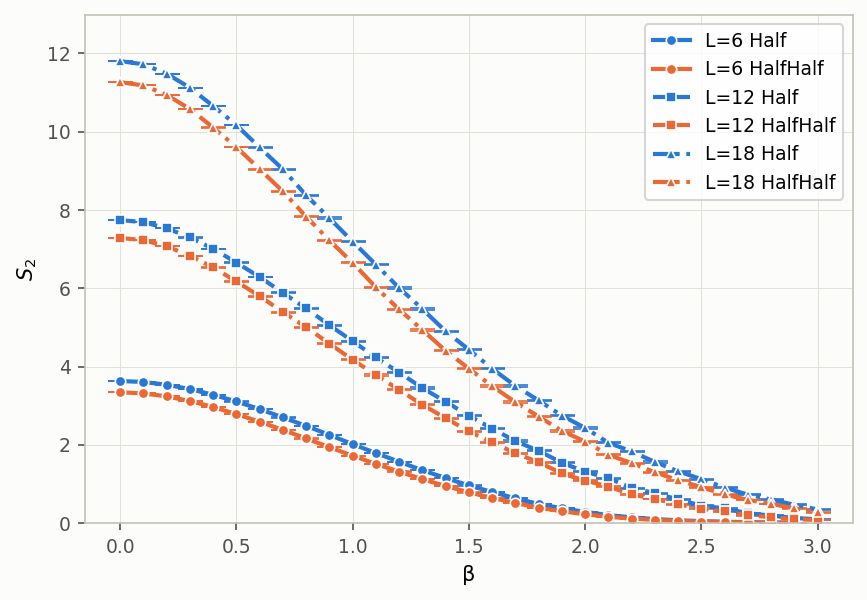

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 颜色 → csv 的列（Half / HalfHalf）
SERIES_COLOR = {"Half": "#2a78d6", "HalfHalf": "#eb6834"}
# 线型 + marker → 文件名里 L 后面的数字
L_LSTYLE = ["-", "--", "-.", ":"]
L_MARKER = ["o", "s", "^", "D", "v", "P", "X"]


def plot_EE(df, ylog=False, ax=None):
    """
    横轴 beta，纵轴 EE ± dEE。

    颜色 = csv 的列（Half / HalfHalf）；线型 + marker = 文件名里 L 后面的数字。
    legend 文字形如 "L=6 Half"、"L=6 HalfHalf"、"L=8 Half" …
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6.6, 4.4), dpi=150)

    Lvals = sorted(df["L"].dropna().unique())
    Lstyle = {v: L_LSTYLE[i % len(L_LSTYLE)] for i, v in enumerate(Lvals)}
    Lmark = {v: L_MARKER[i % len(L_MARKER)] for i, v in enumerate(Lvals)}

    # 实际存在的 (L, 列) 组合，顺序：先按 L、再按列
    pairs = [(Lv, n) for Lv in Lvals for n in COLNAMES
             if not df[(df["type"] == n) & (df["L"] == Lv)].empty]

    for Lv, name in pairs:
        sub = df[(df["type"] == name) & (df["L"] == Lv)].sort_values("beta")
        ax.errorbar(sub["beta"], sub["EE"], yerr=sub["dEE"],
                    color=SERIES_COLOR[name],
                    ecolor=SERIES_COLOR[name],   # 误差棒颜色
                    marker=Lmark[Lv], linestyle=Lstyle[Lv],
                    markersize=5, linewidth=2, capsize=6,
                    markeredgecolor="white", markeredgewidth=0.8)

    lo, hi = df["beta"].min(), df["beta"].max()
    pad = 0.05 * (hi - lo) if hi > lo else 0.5     # 左右各留 5%，端点不贴边框
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_yscale("log" if ylog else "linear")
    if not ylog:
        ax.set_ylim(0, 1.1 * df["EE"].max())

    ax.set_xlabel("β")
    ax.set_ylabel(r"$S_2$")
    ax.grid(True, color="#e1e0d9", linewidth=0.5)
    ax.set_axisbelow(True)
    ax.set_facecolor("#fcfcfb")
    ax.figure.set_facecolor("#fcfcfb")
    for spine in ax.spines.values():
        spine.set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=9)

    ax.legend(handles=[Line2D([], [], color=SERIES_COLOR[n],
                              linestyle=Lstyle[Lv], marker=Lmark[Lv],
                              markersize=5, linewidth=2,
                              markeredgecolor="white", markeredgewidth=0.8)
                       for Lv, n in pairs],
              labels=[f"L={Lv:g} {n}" for Lv, n in pairs],
              loc="upper right", fontsize=9)
    return ax


plot_EE(df)
# plot_EE(df, ylog=True)                 # 对数纵轴版本
# plt.savefig("EE_vs_beta.pdf", bbox_inches="tight")   # 需要导出时取消注释
plt.show()


In [ ]:
# ΔS₂ = S₂^Half − S₂^HalfHalf，随 β 变化
#
# 误差按两者独立传播：dΔS₂ = sqrt(dEE_Half² + dEE_HalfHalf²)
# （同一 (L, β) 下 Half / HalfHalf 是同一批 sweep 的两个观测量，严格说存在关联，
#   这里给的是忽略关联的上界估计。）
_d = df.pivot_table(index=["L", "beta"], columns="type", values="EE")
_dd = df.pivot_table(index=["L", "beta"], columns="type", values="dEE")

dS2 = pd.DataFrame({
    "L": _d.index.get_level_values("L"),
    "beta": _d.index.get_level_values("beta"),
    "dS2": _d["Half"].to_numpy() - _d["HalfHalf"].to_numpy(),
    "ddS2": np.sqrt(_dd["Half"].to_numpy() ** 2 + _dd["HalfHalf"].to_numpy() ** 2),
}).sort_values(["L", "beta"]).reset_index(drop=True)
dS2

In [ ]:
# ΔS₂ 只有一族曲线（L 区分），所以颜色 → L，线型 / marker 仍跟着 L 走
L_COLOR = ["#2a78d6", "#eb6834", "#2f9e44", "#9c36b5", "#c9a227", "#0c8599", "#e03131"]


def plot_dS2(dS2, ax=None, ylog=False):
    """
    横轴 beta，纵轴 ΔS₂ = S₂^Half − S₂^HalfHalf ± dΔS₂。

    颜色 / 线型 / marker 都跟着 L 走，legend 文字形如 "L=6"、"L=12" …
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6.6, 4.4), dpi=150)

    Lvals = sorted(dS2["L"].dropna().unique())
    Lcolor = {v: L_COLOR[i % len(L_COLOR)] for i, v in enumerate(Lvals)}
    Lstyle = {v: L_LSTYLE[i % len(L_LSTYLE)] for i, v in enumerate(Lvals)}
    Lmark = {v: L_MARKER[i % len(L_MARKER)] for i, v in enumerate(Lvals)}

    for Lv in Lvals:
        sub = dS2[dS2["L"] == Lv].sort_values("beta")
        ax.errorbar(sub["beta"], sub["dS2"], yerr=sub["ddS2"],
                    color=Lcolor[Lv],
                    ecolor=Lcolor[Lv],          # 误差棒颜色
                    marker=Lmark[Lv], linestyle=Lstyle[Lv],
                    markersize=5, linewidth=2, capsize=6,
                    markeredgecolor="white", markeredgewidth=0.8,
                    label=f"L={Lv:g}")

    ax.axhline(0.0, color="#c3c2b7", linewidth=1, linestyle="--", zorder=0)

    lo, hi = dS2["beta"].min(), dS2["beta"].max()
    pad = 0.05 * (hi - lo) if hi > lo else 0.5     # 左右各留 5%，端点不贴边框
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_yscale("log" if ylog else "linear")
    if not ylog:
        y = dS2["dS2"]
        span = y.max() - y.min()
        span = span if span > 0 else 1.0
        ax.set_ylim(min(0.0, y.min()) - 0.08 * span, y.max() + 0.08 * span)
    ax.margins(x=0)

    ax.set_xlabel("β")
    ax.set_ylabel(r"$\Delta S_2 = S_2^{\mathrm{Half}} - S_2^{\mathrm{HalfHalf}}$")
    ax.grid(True, color="#e1e0d9", linewidth=0.5)
    ax.set_axisbelow(True)
    ax.set_facecolor("#fcfcfb")
    ax.figure.set_facecolor("#fcfcfb")
    for spine in ax.spines.values():
        spine.set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=9)

    ax.legend(handles=[Line2D([], [], color=Lcolor[Lv],
                              linestyle=Lstyle[Lv], marker=Lmark[Lv],
                              markersize=5, linewidth=2,
                              markeredgecolor="white", markeredgewidth=0.8)
                       for Lv in Lvals],
              labels=[f"L={Lv:g}" for Lv in Lvals],
              loc="best", fontsize=9)
    return ax


plot_dS2(dS2)
# plt.savefig("dS2_vs_beta.pdf", bbox_inches="tight")   # 需要导出时取消注释
plt.show()

./L=12\FreeHCL12_β2.0.csv  L = 12.0  beta = 2.0


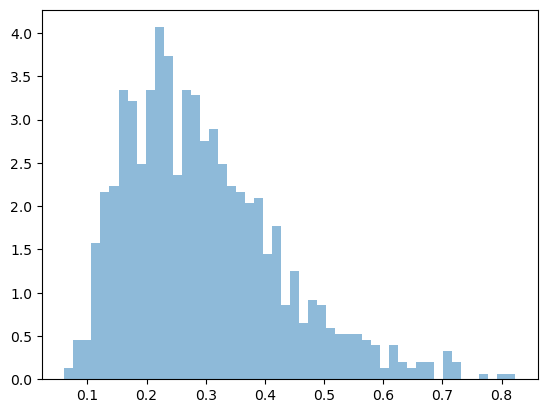

In [6]:
import glob
L=12
beta=2.0
file = sorted(glob.glob(f"./L={L}/*β{beta}*.csv"))[0]
print(file, " L =", extract_L(file), " beta =", extract_beta(file))

data = read_two_cols(file)

plt.hist(data[:, 0], bins=50, density=True, alpha=0.5, label="Half")
plt.show()
